# DGA Domain Detection

This notebook cleans the dataset, creates a balanced sample, extracts ten lexical features, explores the data, tunes three classifiers, evaluates them, and saves the trained models. The model predicts the dataset label. A DGA prediction is not proof that a domain is malicious.

## 1. Imports and configuration

In [2]:
import os
import re
import math
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
DATA_PATH = "datasets/dga2.csv"
MODEL_DIR = "models"

FEATURE_COLUMNS = [
    "domain_length",
    "digit_count",
    "vowel_count",
    "consonant_count",
    "digit_ratio",
    "vowel_ratio",
    "unique_char_ratio",
    "entropy",
    "hyphen_count",
    "max_consonant_sequence"
]

EXPECTED_LABELS = {"benign", "dga"}
VOWEL_PATTERN = r"[aeiou]"
CONSONANT_PATTERN = r"[bcdfghjklmnpqrstvwxyz]"


## 2. Load and inspect the dataset

In [3]:
df = pd.read_csv(DATA_PATH)

required_columns = {"domain", "threat"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")

print("First rows:")
display(df.head())

print("\\nDataset shape:", df.shape)
print("\\nMissing values:")
print(df[["domain", "threat"]].isnull().sum())

print("\\nOriginal class distribution:")
print(df["threat"].value_counts(dropna=False))

print("\\nDuplicate rows:", df.duplicated().sum())


First rows:


,domain,threat
0,ocymmekqogkw,dga
1,eohcbdibsjoiafxnrvddh,dga
2,myhandeczema,benign
3,deummagdbawse,dga
4,vipozacyqexib,dga


\nDataset shape: (16246006, 2)
\nMissing values:
domain    3
threat    0
dtype: int64
\nOriginal class distribution:
threat
dga       8261879
benign    7984127
Name: count, dtype: int64
\nDuplicate rows: 2


## 3. Clean the data

In [4]:
df = df.dropna(subset=["domain", "threat"]).copy()
df["domain"] = df["domain"].astype(str).str.lower().str.strip()
df["threat"] = df["threat"].astype(str).str.lower().str.strip()

# Remove empty domain strings and exact duplicate records.
df = df[df["domain"] != ""].drop_duplicates().reset_index(drop=True)

unexpected_labels = set(df["threat"].unique()) - EXPECTED_LABELS
if unexpected_labels:
    raise ValueError(
        f"Unexpected threat labels: {sorted(unexpected_labels)}. "
        f"Expected only {sorted(EXPECTED_LABELS)}."
    )

print("Cleaned dataset shape:", df.shape)
print("\\nCleaned class distribution:")
print(df["threat"].value_counts())


Cleaned dataset shape: (16246003, 2)
\nCleaned class distribution:
threat
dga       8261879
benign    7984124
Name: count, dtype: int64


## 4. Create a balanced sample

In [5]:
class_counts = df["threat"].value_counts()
if not EXPECTED_LABELS.issubset(set(class_counts.index)):
    raise ValueError("Both 'benign' and 'dga' classes must be present.")

SAMPLES_PER_CLASS = 10_000
if (class_counts < SAMPLES_PER_CLASS).any():
    raise ValueError(
        f"At least {SAMPLES_PER_CLASS:,} records per class are required. "
        f"Available counts: {class_counts.to_dict()}"
    )

sample = (
    df.groupby("threat", group_keys=False)
      .sample(n=SAMPLES_PER_CLASS, random_state=RANDOM_STATE)
      .sample(frac=1, random_state=RANDOM_STATE)
      .reset_index(drop=True)
)

print("Sample shape:", sample.shape)
print("\\nSample class distribution:")
print(sample["threat"].value_counts())
display(sample.head())


Sample shape: (20000, 2)
\nSample class distribution:
threat
dga       10000
benign    10000
Name: count, dtype: int64


,domain,threat
0,gsibxkiguh,dga
1,92400,benign
2,millerstrategicmarketing,benign
3,stonesthrowliving,benign
4,5evhfjchr7qfmvnv2fei3d4o,dga


## 5. Define lexical feature extraction

In [6]:
def calculate_entropy(domain: str) -> float:
    """Calculate Shannon character entropy in bits per character."""
    if not domain:
        return 0.0

    counts = Counter(domain)
    length = len(domain)
    return -sum(
        (count / length) * math.log2(count / length)
        for count in counts.values()
    )


def max_consonant_sequence(domain: str) -> int:
    """Return the longest uninterrupted run of ASCII English consonants."""
    sequences = re.findall(CONSONANT_PATTERN + r"+", domain)
    return max((len(sequence) for sequence in sequences), default=0)


def extract_domain_features(domain: str) -> dict:
    """Extract the same ten lexical features used by model training."""
    if pd.isna(domain):
        domain = ""
    domain = str(domain).lower().strip()

    length = len(domain)
    digit_count = sum(char.isdigit() for char in domain)
    vowel_count = len(re.findall(VOWEL_PATTERN, domain))
    consonant_count = len(re.findall(CONSONANT_PATTERN, domain))
    hyphen_count = domain.count("-")

    return {
        "domain_length": length,
        "digit_count": digit_count,
        "vowel_count": vowel_count,
        "consonant_count": consonant_count,
        "digit_ratio": digit_count / length if length else 0.0,
        "vowel_ratio": vowel_count / length if length else 0.0,
        "unique_char_ratio": len(set(domain)) / length if length else 0.0,
        "entropy": calculate_entropy(domain),
        "hyphen_count": hyphen_count,
        "max_consonant_sequence": max_consonant_sequence(domain)
    }


feature_frame = pd.DataFrame(
    sample["domain"].apply(extract_domain_features).tolist(),
    index=sample.index
)

sample = pd.concat([sample, feature_frame], axis=1)

# Keep the feature order explicit and stable.
X = sample[FEATURE_COLUMNS].copy()
y = sample["threat"].map({"benign": 0, "dga": 1}).astype(int)

print("Feature matrix shape:", X.shape)
display(sample[["domain", "threat"] + FEATURE_COLUMNS].head())


Feature matrix shape: (20000, 10)


,domain,threat,domain_length,digit_count,vowel_count,consonant_count,digit_ratio,vowel_ratio,unique_char_ratio,entropy,hyphen_count,max_consonant_sequence
0,gsibxkiguh,dga,10,0,3,7,0.000000,0.300000,0.800000,2.921928,0,3
1,92400,benign,5,5,0,0,1.000000,0.000000,0.800000,1.921928,0,0
2,millerstrategicmarketing,benign,24,0,8,16,0.000000,0.333333,0.500000,3.459148,0,4
3,stonesthrowliving,benign,17,0,5,12,0.000000,0.294118,0.705882,3.499228,0,4
4,5evhfjchr7qfmvnv2fei3d4o,dga,24,5,4,15,0.208333,0.166667,0.750000,4.022055,0,7


## 6. Exploratory feature analysis

In [7]:
print("Feature summary:")
display(sample[FEATURE_COLUMNS].describe())

print("\\nMean feature values by class:")
display(sample.groupby("threat")[FEATURE_COLUMNS].mean().T)


Feature summary:


,domain_length,digit_count,vowel_count,consonant_count,digit_ratio,vowel_ratio,unique_char_ratio,entropy,hyphen_count,max_consonant_sequence
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,13.470050,0.772750,3.963950,8.672050,0.060523,0.292508,0.761261,3.094368,0.061300,3.867100
std,5.821546,2.285031,2.551779,4.087583,0.189772,0.144964,0.139504,0.505302,0.273397,2.540268
min,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.291667,0.811278,0.000000,0.000000
25%,9.000000,0.000000,2.000000,6.000000,0.000000,0.187500,0.666667,2.751629,0.000000,2.000000
50%,12.000000,0.000000,4.000000,8.000000,0.000000,0.312500,0.764706,3.121928,0.000000,3.000000
75%,17.000000,0.000000,5.000000,11.000000,0.000000,0.400000,0.857143,3.440760,0.000000,5.000000
max,41.000000,27.000000,19.000000,26.000000,1.000000,0.875000,1.000000,4.753226,5.000000,24.000000


\nMean feature values by class:


threat,benign,dga
domain_length,11.785700,15.154400
digit_count,0.424500,1.121000
vowel_count,4.247500,3.680400
consonant_count,6.991100,10.353000
digit_ratio,0.068708,0.052339
vowel_ratio,0.344280,0.240737
unique_char_ratio,0.766230,0.756293
entropy,2.924572,3.264164
hyphen_count,0.122600,0.000000
max_consonant_sequence,2.474300,5.259900


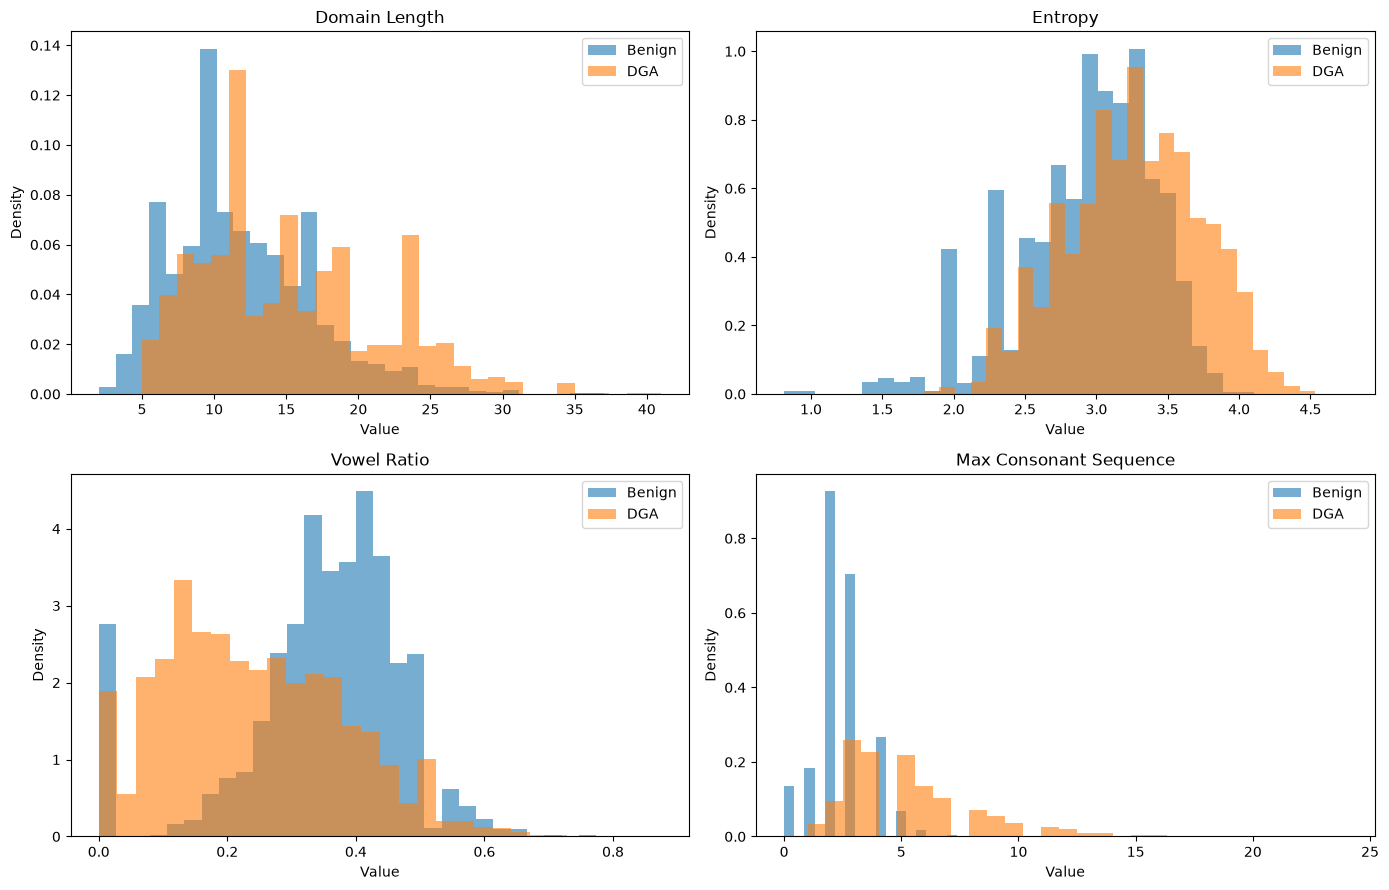

In [8]:
features_to_plot = [
    "domain_length",
    "entropy",
    "vowel_ratio",
    "max_consonant_sequence"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, feature in zip(axes.flatten(), features_to_plot):
    benign = sample.loc[sample["threat"] == "benign", feature]
    dga = sample.loc[sample["threat"] == "dga", feature]

    ax.hist(benign, bins=30, alpha=0.6, density=True, label="Benign")
    ax.hist(dga, bins=30, alpha=0.6, density=True, label="DGA")
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()


In [9]:
correlation_matrix = sample[FEATURE_COLUMNS].corr()

upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)
correlation_pairs = (
    upper_triangle.stack()
    .sort_values(key=abs, ascending=False)
)

print("Feature correlations (largest absolute correlations first):")
display(correlation_pairs)


Feature correlations (largest absolute correlations first):


domain_length           consonant_count           0.864622
                        entropy                   0.793318
digit_count             digit_ratio               0.763037
consonant_count         entropy                   0.761926
vowel_count             vowel_ratio               0.709970
                                                    ...   
max_consonant_sequence  vowel_ratio                    NaN
                        unique_char_ratio              NaN
                        entropy                        NaN
                        hyphen_count                   NaN
                        max_consonant_sequence         NaN
Length: 100, dtype: float64

## 7. Train/test split

The test split is held aside from GridSearchCV. The tuning process uses only the training split.


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\\nTraining class distribution:")
print(y_train.value_counts())
print("\\nTesting class distribution:")
print(y_test.value_counts())


Training samples: 16000
Testing samples: 4000
\nTraining class distribution:
threat
1    8000
0    8000
Name: count, dtype: int64
\nTesting class distribution:
threat
1    2000
0    2000
Name: count, dtype: int64


## 8. Hyperparameter tuning with GridSearchCV

In [11]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Logistic Regression: scaling is fitted within each CV training fold.
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000))
])

lr_grid = {
    "classifier__C": [0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"],
    "classifier__solver": ["lbfgs"]
}

lr_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

print("========== LOGISTIC REGRESSION ==========")
lr_search.fit(X_train, y_train)
print("Best parameters:", lr_search.best_params_)
print("Best CV F1:", lr_search.best_score_)


========== LOGISTIC REGRESSION ==========
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'classifier__C': 0.1, 'classifier__class_weight': None, 'classifier__solver': 'lbfgs'}
Best CV F1: 0.7974418331035463


In [12]:
rf_grid = {
    "n_estimators": [200, 400],
    "max_depth": [None, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "class_weight": ["balanced"]
}

rf_search = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=1
    ),
    param_grid=rf_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

print("========== RANDOM FOREST ==========")
rf_search.fit(X_train, y_train)
print("Best parameters:", rf_search.best_params_)
print("Best CV F1:", rf_search.best_score_)


========== RANDOM FOREST ==========
Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best parameters: {'class_weight': 'balanced', 'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
Best CV F1: 0.8243431080961021


In [13]:
gb_grid = {
    "learning_rate": [0.05, 0.1],
    "max_iter": [150, 250],
    "max_leaf_nodes": [15, 31],
    "l2_regularization": [0, 1]
}

gb_search = GridSearchCV(
    estimator=HistGradientBoostingClassifier(
        random_state=RANDOM_STATE
    ),
    param_grid=gb_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

print("========== HISTOGRAM GRADIENT BOOSTING ==========")
gb_search.fit(X_train, y_train)
print("Best parameters:", gb_search.best_params_)
print("Best CV F1:", gb_search.best_score_)


========== HISTOGRAM GRADIENT BOOSTING ==========
Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best parameters: {'l2_regularization': 0, 'learning_rate': 0.05, 'max_iter': 250, 'max_leaf_nodes': 31}
Best CV F1: 0.830865837815916


## 9. Evaluate the tuned models on the test split

In [14]:
best_models = {
    "Logistic Regression": lr_search.best_estimator_,
    "Random Forest": rf_search.best_estimator_,
    "HistGradientBoosting": gb_search.best_estimator_
}

evaluation_rows = []
test_predictions = {}

for name, model in best_models.items():
    predictions = model.predict(X_test)
    test_predictions[name] = predictions

    # All three selected estimators support predict_proba.
    probabilities = model.predict_proba(X_test)[:, 1]

    evaluation_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Best CV F1": (
            lr_search.best_score_ if name == "Logistic Regression"
            else rf_search.best_score_ if name == "Random Forest"
            else gb_search.best_score_
        )
    })

evaluation_df = pd.DataFrame(evaluation_rows).set_index("Model")
display(evaluation_df.round(4))


,Accuracy,Precision,Recall,F1,ROC-AUC,Best CV F1
Model,,,,,,
Logistic Regression,0.8140,0.8462,0.7675,0.8049,0.8978,0.7974
Random Forest,0.8390,0.8626,0.8065,0.8336,0.9203,0.8243
HistGradientBoosting,0.8422,0.8780,0.7950,0.8344,0.9275,0.8309


\n========== Logistic Regression ==========
              precision    recall  f1-score   support

      Benign       0.79      0.86      0.82      2000
         DGA       0.85      0.77      0.80      2000

    accuracy                           0.81      4000
   macro avg       0.82      0.81      0.81      4000
weighted avg       0.82      0.81      0.81      4000



,Predicted Benign,Predicted DGA
Actual Benign,1721,279
Actual DGA,465,1535


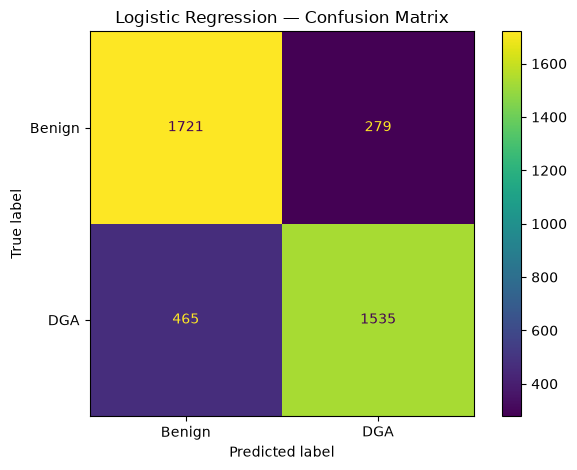

\n========== Random Forest ==========
              precision    recall  f1-score   support

      Benign       0.82      0.87      0.84      2000
         DGA       0.86      0.81      0.83      2000

    accuracy                           0.84      4000
   macro avg       0.84      0.84      0.84      4000
weighted avg       0.84      0.84      0.84      4000



,Predicted Benign,Predicted DGA
Actual Benign,1743,257
Actual DGA,387,1613


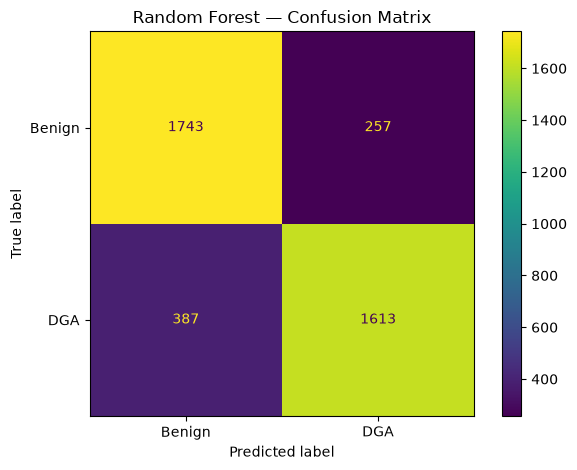

\n========== HistGradientBoosting ==========
              precision    recall  f1-score   support

      Benign       0.81      0.89      0.85      2000
         DGA       0.88      0.80      0.83      2000

    accuracy                           0.84      4000
   macro avg       0.85      0.84      0.84      4000
weighted avg       0.85      0.84      0.84      4000



,Predicted Benign,Predicted DGA
Actual Benign,1779,221
Actual DGA,410,1590


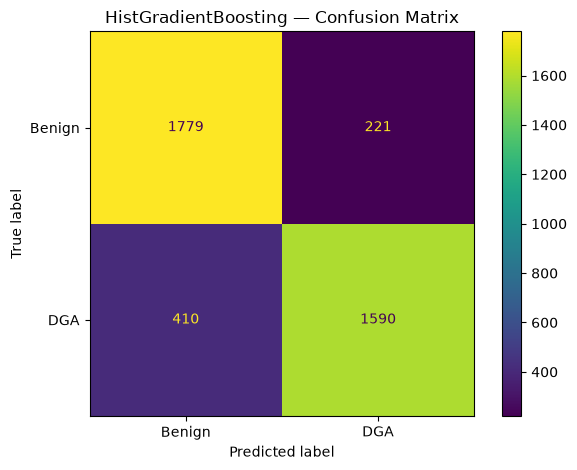

In [15]:
for name, model in best_models.items():
    print(f"\\n========== {name} ==========")
    predictions = test_predictions[name]

    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=["Benign", "DGA"],
        zero_division=0
    ))

    cm = confusion_matrix(y_test, predictions, labels=[0, 1])
    display(pd.DataFrame(
        cm,
        index=["Actual Benign", "Actual DGA"],
        columns=["Predicted Benign", "Predicted DGA"]
    ))

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Benign", "DGA"]
    ).plot()
    plt.title(f"{name} — Confusion Matrix")
    plt.tight_layout()
    plt.show()


In [16]:
# Exact domain duplicates and conflicting labels must be examined before modelling.
domain_label_counts = df.groupby("domain")["threat"].nunique()
conflicting_domains = domain_label_counts[domain_label_counts > 1]
repeated_domains = df["domain"].value_counts()

print("Unique domains:", df["domain"].nunique())
print("Domains appearing more than once:", int((repeated_domains > 1).sum()))
print("Domains with conflicting labels:", len(conflicting_domains))
if len(conflicting_domains):
    display(df[df["domain"].isin(conflicting_domains.index)].sort_values("domain").head(30))


Unique domains: 16246003
Domains appearing more than once: 0
Domains with conflicting labels: 0


In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.metrics import (
    average_precision_score, precision_recall_curve,
    PrecisionRecallDisplay, roc_curve
)
from sklearn.linear_model import LogisticRegression

X_all = sample[FEATURE_COLUMNS].copy()
domains_all = sample["domain"].astype(str).values
y_all = y.values
indices = np.arange(len(sample))
train_idx, test_idx = train_test_split(
    indices, test_size=0.20, random_state=RANDOM_STATE, stratify=y_all
)

In [18]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

char_numeric_features = ColumnTransformer(
    transformers=[
        ("char_ngrams", TfidfVectorizer(
            analyzer="char", ngram_range=(2, 4), min_df=2,
            max_features=50000, sublinear_tf=True
        ), "domain"),
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), FEATURE_COLUMNS)
    ],
    remainder="drop"
)

ngram_model = Pipeline([
    ("features", char_numeric_features),
    ("classifier", LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced"))
])

model_frame = sample[["domain"] + FEATURE_COLUMNS].copy()
X_train_mix = model_frame.iloc[train_idx]
X_test_mix = model_frame.iloc[test_idx]
y_train_mix = y_all[train_idx]
y_test_mix = y_all[test_idx]

ngram_model.fit(X_train_mix, y_train_mix)
ngram_prob = ngram_model.predict_proba(X_test_mix)[:, 1]
ngram_pred = (ngram_prob >= 0.5).astype(int)
print(classification_report(y_test_mix, ngram_pred, target_names=["Benign", "DGA"]))
print("ROC-AUC:", roc_auc_score(y_test_mix, ngram_prob))
print("PR-AUC / Average precision:", average_precision_score(y_test_mix, ngram_prob))


              precision    recall  f1-score   support

      Benign       0.94      0.97      0.95      2000
         DGA       0.97      0.94      0.95      2000

    accuracy                           0.95      4000
   macro avg       0.95      0.95      0.95      4000
weighted avg       0.95      0.95      0.95      4000

ROC-AUC: 0.9890945
PR-AUC / Average precision: 0.9898091475325093


   threshold  precision  recall      f1  false_positive_rate  \
0        0.3     0.7514  0.9145  0.8250               0.3025   
1        0.4     0.8250  0.8555  0.8400               0.1815   
2        0.5     0.8780  0.7950  0.8344               0.1105   
3        0.6     0.9162  0.7540  0.8272               0.0690   
4        0.7     0.9440  0.6995  0.8036               0.0415   

   false_negative_rate  true_negatives  false_positives  false_negatives  \
0               0.0855            1395              605              171   
1               0.1445            1637              363              289   
2               0.2050            1779              221              410   
3               0.2460            1862              138              492   
4               0.3005            1917               83              601   

   true_positives  
0            1829  
1            1711  
2            1590  
3            1508  
4            1399  
Average precision: 0.9362934589329324


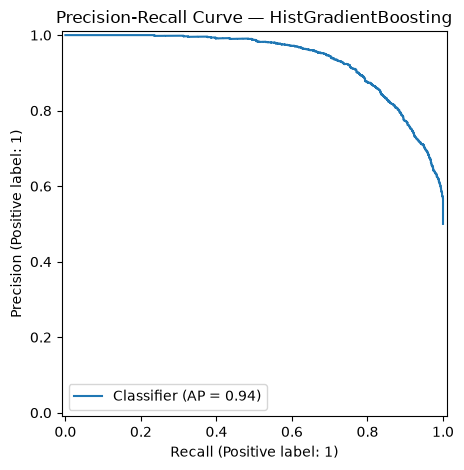

In [19]:
def binary_metrics_at_threshold(y_true, probabilities, threshold=0.5):
    pred = (np.asarray(probabilities) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "threshold": threshold,
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "false_positive_rate": fp / (fp + tn) if (fp + tn) else 0.0,
        "false_negative_rate": fn / (fn + tp) if (fn + tp) else 0.0,
        "true_negatives": tn, "false_positives": fp,
        "false_negatives": fn, "true_positives": tp
    }

best_lexical_model = gb_search.best_estimator_
base_prob = best_lexical_model.predict_proba(X_test)[:, 1]
print(pd.DataFrame([
    binary_metrics_at_threshold(y_test, base_prob, t)
    for t in [0.30, 0.40, 0.50, 0.60, 0.70]
]).round(4))

print("Average precision:", average_precision_score(y_test, base_prob))
PrecisionRecallDisplay.from_predictions(y_test, base_prob)
plt.title("Precision-Recall Curve — HistGradientBoosting")
plt.tight_layout(); plt.show()


In [21]:

import os
import joblib

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)

# Create the models directory
os.makedirs(MODEL_DIR, exist_ok=True)

# Collect the three trained numerical models
numeric_models = best_models

# Evaluate the character n-gram model
ngram_metrics = {
    "accuracy": float(accuracy_score(y_test_mix, ngram_pred)),
    "precision": float(precision_score(y_test_mix, ngram_pred, zero_division=0)),
    "recall": float(recall_score(y_test_mix, ngram_pred, zero_division=0)),
    "f1": float(f1_score(y_test_mix, ngram_pred, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_test_mix, ngram_prob)),
    "average_precision": float(
        average_precision_score(y_test_mix, ngram_prob)
    ),
}

# Prepare the complete model bundle
model_bundle = {
    "numeric_models": numeric_models,
    "ngram_model": ngram_model,
    "feature_columns": FEATURE_COLUMNS,
    "label_mapping": {
        0: "benign",
        1: "dga"
    },
    "evaluation_metrics": evaluation_df.to_dict(orient="index"),
    "ngram_metrics": ngram_metrics,
    "metadata": {
        "project": "Supervised lexical DGA domain detection",
        "feature_version": 1,
        "random_state": RANDOM_STATE,
        "samples_per_class": SAMPLES_PER_CLASS,
        "training_rows": int(len(X_train)),
        "test_rows": int(len(X_test)),
        "models": (
            list(numeric_models.keys())
            + ["Character n-gram Logistic Regression"]
        ),
    },
}

# Export using Joblib
model_path = os.path.join(
    MODEL_DIR,
    "dga_supervised_models.joblib"
)

joblib.dump(model_bundle, model_path, compress=3)

print("Model export completed.")
print("Saved to:", os.path.abspath(model_path))
print(
    "Bundle size:",
    round(os.path.getsize(model_path) / (1024 * 1024), 2),
    "MB"
)

# Verify the exported bundle
reloaded_bundle = joblib.load(model_path)

print("\nExport verification:")
print("Numeric models:", list(
    reloaded_bundle["numeric_models"].keys()
))
print("N-gram model:", "ngram_model" in reloaded_bundle)
print("Feature count:", len(
    reloaded_bundle["feature_columns"]
))
print("Export verification: successful")


Model export completed.
Saved to: c:\Users\Joshua Sanctus\Downloads\DGA\models\dga_supervised_models.joblib
Bundle size: 8.12 MB

Export verification:
Numeric models: ['Logistic Regression', 'Random Forest', 'HistGradientBoosting']
N-gram model: True
Feature count: 10
Export verification: successful
